# Lab 4 — Gas absorption and column height

Remove a dilute solute from a gas using a countercurrent solvent. Connect material balances, ideal stages, efficiency and a hydraulic screening calculation.

**Time budget: 6 hours, including a short break and submission.** Work in pairs,
but both partners must be able to explain every figure and calculation.
Prerequisites: material and energy balances, algebra, basic Python arrays and plots.
Use SI units unless explicitly stated. All case data are synthetic teaching values,
not measurements or validated equipment specifications.

Submit this notebook with outputs and a short engineering recommendation (300–500 words).
Include assumptions, a labelled flowsheet, equations, units, balance checks,
at least one sensitivity plot, and a discussion of model limitations.
Optional extensions are outside the six-hour budget.

## 1. Setup and prediction — 30 minutes
Before computing, sketch the apparatus and predict which parameter most strongly
affects its size or energy demand. Explain your reasoning in two sentences.

Locally, place `helpers.py` beside this notebook and install the root requirements.
In Colab, upload both files using the Files panel. Alternatively, after the repository
is published, set `HELPER_URL` below to the raw GitHub URL of this lab's `helpers.py`.
Use a commit SHA in the URL for reproducible teaching. Only download code from a
repository you trust. Each lab needs only its own helper file.

In [ ]:
from pathlib import Path
from urllib.request import urlretrieve

HELPER_URL = ""  # e.g. https://raw.githubusercontent.com/OWNER/REPO/COMMIT/lab_01_flow/helpers.py
if not Path("helpers.py").exists():
    if not HELPER_URL:
        raise FileNotFoundError("Upload this lab's helpers.py or set HELPER_URL, then rerun.")
    urlretrieve(HELPER_URL, "helpers.py")

import numpy as np
import matplotlib.pyplot as plt
import helpers as h

## See the whole system

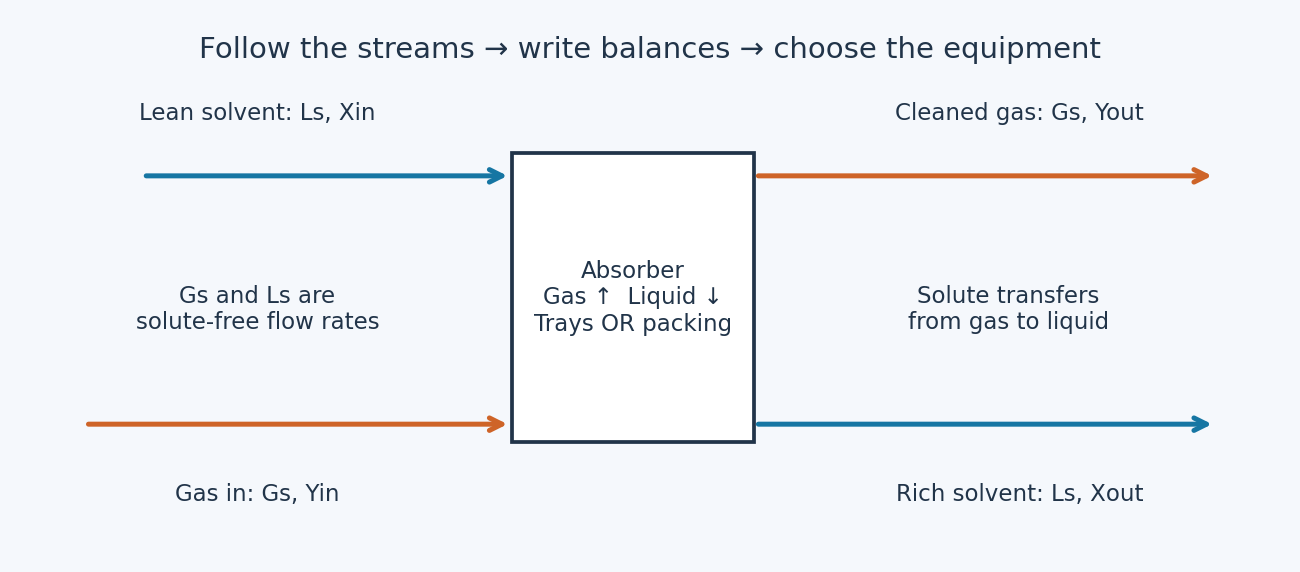

Schematic only: equipment sizes, heights and pipe lengths are not to scale.
Trace each stream with your finger. Identify what enters, what leaves, and where
energy is added or removed. Match the labels to the variables in the model below.

## Model and assumptions
    Isothermal, dilute, nonreacting absorption with constant solute-free gas and solvent
    flow rates $G_s,L_s$ (kmol/h). Use mole ratios $Y=y/(1-y)$ and $X=x/(1-x)$.
    Assume the hypothetical equilibrium relation $Y^*=mX$, with $m=1.5$.
    The operating line is $Y=Y_{out}+(L_s/G_s)(X-X_{in})$.
    Balance: $L_s(X_{out}-X_{in})=G_s(Y_{in}-Y_{out})$.
    For this linear case, $L_{min}/G_s=(Y_{in}-Y_{out})/(Y_{in}/m-X_{in})$.
    Starting at $Y_1=Y_{out}$, equilibrium gives $X_n=Y_n/m$ and the balance gives
    $Y_{n+1}=Y_{out}+(L_s/G_s)(X_n-X_{in})$. Stop once $Y_{n+1}\ge Y_{in}$.
    Count the last stage in full. Ideal stages describe equilibrium contacts, not packing height.
    For trays use an assumed overall efficiency; for packing use an independently supplied
    HETP. Neither can be inferred from equilibrium data alone.

### Worked example: follow a solute through two contacts
Gas enters the bottom and solvent enters the top. Count contacts from the top,
where the clean-gas target and fresh-solvent composition are known.
For a small example use Gs = 100 kmol/h, Ls = 300 kmol/h, m = 1.5,
Xin = 0 and Yout = 0.002. The first equilibrium liquid ratio is 0.001333;
the next gas ratio is 0.006. Repeat the same two operations for contact two.

In [ ]:
ex_G, ex_L, ex_m = 100.0, 300.0, 1.5
ex_Xin, ex_Yout = 0.0, 0.002
ex_y = ex_Yout
ex_points = [(ex_Xin, ex_y)]
for ex_n in range(1, 3):
    ex_x = ex_y / ex_m  # horizontal move to equilibrium
    ex_points.append((ex_x, ex_y))
    ex_y = ex_Yout + ex_L/ex_G * (ex_x-ex_Xin)  # vertical to operating line
    ex_points.append((ex_x, ex_y))
    print(f"Contact {ex_n}: X = {ex_x:.6f}; next Y = {ex_y:.6f}")
ex_grid = np.linspace(0, 0.006, 100)
plt.figure(figsize=(6, 5))
plt.plot(ex_grid, ex_m*ex_grid, label="Equilibrium")
plt.plot(ex_grid, ex_Yout+ex_L/ex_G*(ex_grid-ex_Xin), label="Operating line")
ex_steps = np.array(ex_points)
plt.plot(ex_steps[:, 0], ex_steps[:, 1], "o-", label="First two contacts")
plt.xlabel("Liquid mole ratio X"); plt.ylabel("Gas mole ratio Y")
plt.legend(); plt.grid(); plt.show()

**Try a small change:** Change Ls from 300 to 400 kmol/h. Does each step cover more or less of the required gas-composition change? Extend the loop until it reaches Yin = 0.03, checking first that solvent flow exceeds its minimum.

Spend about 20 minutes on this example within the model-development time below. Predict → run → explain. Then move to the main case.

### Main design case

The next cell defines the larger case used in the assessed tasks. Example variables use `ex_` so you can rerun them without changing this case.

In [ ]:
Gs, Yin, Yout, Xin, m = 100.0, 0.03, 0.003, 0.0, 1.5
Lmin = Gs*(Yin-Yout)/(Yin/m-Xin)
Ls = 1.5*Lmin
Xout = Xin + Gs/Ls*(Yin-Yout)
print(f"Minimum solvent: {Lmin:.2f} kmol/h; selected: {Ls:.2f} kmol/h")
X = np.linspace(0, Yin/m*1.1, 200)
plt.plot(X, m*X, label="Equilibrium")
plt.plot(X, Yout+Ls/Gs*(X-Xin), label="Operating line")
plt.xlabel("Liquid mole ratio X"); plt.ylabel("Gas mole ratio Y")
plt.legend(); plt.grid()

## 2. Balance and feasibility — 75 minutes

Convert inlet and outlet gas ratios to mole fractions. Calculate solvent outlet composition and solute removal in kmol/h. Verify the solute balance. Derive L_min from the bottom pinch and explain why the selected flow must exceed it. Check the driving force at both column ends.

**Suggested route:** (1) List known values and units. (2) Write the balance on
    paper. (3) Translate one equation at a time into named Python variables.
    (4) Print intermediate results and compare with a hand calculation.
    Start from the worked-example cell above rather than an empty page.

In [ ]:
# TODO: balance, mole fractions and pinch construction.

**Your interpretation:** Replace this text with your reasoning, units, and evidence.

## 3. Count ideal stages — 90 minutes

Implement the recurrence above and plot the staircase: start at (Xin,Yout), step horizontally to equilibrium, then vertically to the operating line. Include a non-progress check and 300-stage cap. Compare with h.stage_count. Sweep L/L_min from 1.05 to 2.5 and show how solvent demand trades against stage count.

**Suggested route:** Adapt the short example into a reusable function.
    Keep the base-case parameters outside the loop. Print the first three iterations
    before running a full search. Add the stopping rule, then a maximum iteration
    count and a clear error for infeasible inputs. Compare one validated result
    with the helper before making a parameter sweep.

In [ ]:
# TODO: independent stage counter, staircase and solvent sweep.

**Your interpretation:** Replace this text with your reasoning, units, and evidence.

## 4. Height and hydraulic screening — 75 minutes

At the base case compare a tray column with overall efficiency 0.60 and tray spacing 0.45 m against packing with assumed HETP 0.6–1.2 m. Report active heights separately. For packing, use area 1.0 m², gas volumetric flow 0.8 m³/s, void fraction 0.70, equivalent particle diameter 0.025 m, gas density 1.2 kg/m³ and viscosity 1.8e-5 Pa s. Evaluate h.ergun_gradient and multiply by packed height. Discuss the credibility of treating this irrigated packing as a dry bed.

**Suggested route:** Copy your validated base-case calculation. Change one
    parameter at a time in a short for-loop, store results in a list, then plot.
    Label infeasible designs explicitly. First compare two cases by hand so you
    know what trend to expect.

In [ ]:
# TODO: height ranges and dry-bed pressure-drop estimates.

**Your interpretation:** Replace this text with your reasoning, units, and evidence.

## 5. Robustness and break — 45 minutes

Take a 10-minute break. Change m by ±20% at fixed selected solvent flow. Recompute the minimum solvent requirement before counting stages; label infeasible cases. Explain why the dry Ergun estimate cannot predict flooding, liquid holdup or actual wet pressure drop. List the vendor/experimental data needed to proceed.

**Suggested route:** State what stays fixed in this experiment. Use at least
    five parameter values, include the base case, and report the change relative
    to it. Explain the physical reason for the trend before choosing a design.

In [ ]:
# TODO: equilibrium sensitivity and feasibility table.

**Your interpretation:** Replace this text with your reasoning, units, and evidence.

## 6. Engineering recommendation and submission — 45 minutes
Choose a design and support it with numbers. State what would need measuring before
using it in practice. Check your balances and inspect every axis label and unit.
Restart the kernel and run all completed cells in order before submission.

**Peer check:** Ask your partner to explain one equation, one numerical check,
and one reason the model could fail. Record any revision this discussion prompted.

## Optional extension

Compare the stage model with a continuous transfer-unit model. State which additional mass-transfer coefficients and interfacial-area data are needed.